# Stage 2: Inferential Statistics

## Objective

This stage examines how players' perceptions of luck, the pity system, and pricing are related to satisfaction. It also tests whether satisfaction is associated with the intention to keep playing and whether spending more during promotions is associated with monthly spending group.

The analysis uses 510 cleaned survey responses from adult Vietnamese gacha players recruited through online communities. Because recruitment was non-random, we interpret the findings in the context of the survey sample.

## 1. Load the survey data

Load `Dataset/gacha_clean.csv` and check that the dataset contains the columns needed for Stage 2.

In [1]:
from pathlib import Path

import pandas as pd

# Tìm CSV khi notebook chạy từ gốc repo hoặc từ Data_Analysis.
csv_path = Path("Dataset/gacha_clean.csv")
if not csv_path.is_file():
    csv_path = Path("../Dataset/gacha_clean.csv")

df = pd.read_csv(csv_path, encoding="utf-8-sig")

print(f"Dữ liệu: {df.shape[0]} dòng, {df.shape[1]} cột")

Dữ liệu: 510 dòng, 52 cột


## 2. Spearman rank correlations

We use Spearman's rank correlation to examine four associations in the survey data.

- H1: Perceived luck (`LUCK`) and satisfaction (`SAT`).
- H2: Perceived fairness of the pity system (`PITY2`) and satisfaction (`SAT`).
- H3: Perceived price fairness (`PRICE`) and satisfaction (`SAT`).
- H4: Satisfaction (`SAT`) and intention to keep playing (`RET1`).

For each pair, the null hypothesis is that Spearman's rho is zero. We report the sample size, rho, a bootstrap 95% confidence interval, and a two-sided p-value.

In [2]:
import numpy as np
from scipy.stats import spearmanr

pairs = [
    ("H1", "LUCK", "SAT"),
    ("H2", "PITY2", "SAT"),
    ("H3", "PRICE", "SAT"),
    ("H4", "SAT", "RET1"),
]

# Cố định seed để kết quả bootstrap lặp lại được.
rng = np.random.default_rng(24521386)
rows = []

for hypothesis, x_col, y_col in pairs:
    # Chỉ giữ người có đủ điểm ở cả hai cột.
    x, y = df[[x_col, y_col]].dropna().to_numpy().T
    n = len(x)
    rho, p_raw = spearmanr(x, y)

    bootstrap_rhos = np.empty(5000)

    for i in range(len(bootstrap_rhos)):
        # Lấy lại mẫu theo dòng để giữ nguyên cặp điểm của mỗi người.
        indices = rng.integers(0, n, size=n)
        bootstrap_rhos[i] = spearmanr(x[indices], y[indices]).statistic

    # Lấy phân vị 2,5% và 97,5% làm hai cận của CI 95%.
    ci_low, ci_high = np.quantile(bootstrap_rhos, [0.025, 0.975])

    rows.append({
        "hypothesis": hypothesis,
        "x": x_col,
        "y": y_col,
        "n": n,
        "rho": rho,
        "ci_low": ci_low,
        "ci_high": ci_high,
        "p_raw": p_raw,
    })

spearman_results = pd.DataFrame(rows)
display(spearman_results.round({"rho": 4, "ci_low": 4, "ci_high": 4}))

,hypothesis,x,y,n,rho,ci_low,ci_high,p_raw
0,H1,LUCK,SAT,510,0.3076,0.2194,0.3925,1.226760e-12
1,H2,PITY2,SAT,510,0.4432,0.3657,0.5153,5.900252e-26
2,H3,PRICE,SAT,510,0.4537,0.3820,0.5235,2.905283e-27
3,H4,SAT,RET1,510,0.5043,0.4342,0.5698,2.988914e-34


## 3. Chi-square test of independence

We test whether reporting higher spending during promotions (`PROMO`) is associated with monthly spending group (`SPEND_MONTH4`). The null hypothesis is that the two variables are independent.

We check the expected cell counts and report the chi-square statistic, degrees of freedom, p-value, and Cramér's V.

In [3]:
from scipy.stats import chi2_contingency

# Đếm số người theo câu trả lời PROMO và nhóm chi tiêu tháng.
observed = pd.crosstab(df["PROMO"], df["SPEND_MONTH4"])
display(observed)

chi2, p_chi, dof, expected = chi2_contingency(observed)
n_chi = observed.to_numpy().sum()

# Cramér's V đo độ mạnh của mối liên hệ.
n_rows, n_cols = observed.shape
cramers_v = np.sqrt(chi2 / (n_chi * min(n_rows - 1, n_cols - 1)))

print(f"Minimum expected count: {expected.min():.2f}")
print(f"Chi-square({dof}) = {chi2:.4f}, p = {p_chi:.3g}")
print(f"n = {n_chi}, Cramér's V = {cramers_v:.4f}")

SPEND_MONTH4,0.0,1.0,2.0,3.0
PROMO,,,,
No,200,77,72,6
Yes,18,33,59,45


Minimum expected count: 15.50
Chi-square(3) = 144.4402, p = 4.17e-31
n = 510, Cramér's V = 0.5322


## 4. Holm correction and results summary

We apply the Holm correction jointly to the five p-values from Stage 2. The results table includes both the original and adjusted p-values. We use the adjusted p-values to assess statistical significance at the 0.05 level.

In [4]:
from statsmodels.stats.multitest import multipletests

summary = spearman_results.rename(columns={"rho": "effect_size"}).copy()
summary["test"] = "Spearman"
summary["effect"] = "Spearman's rho"
summary["statistic"] = summary["effect_size"]
summary["df"] = pd.NA

chi_result = pd.DataFrame([{
    "hypothesis": "Promotion",
    "x": "PROMO",
    "y": "SPEND_MONTH4",
    "n": n_chi,
    "test": "Chi-square",
    "statistic": chi2,
    "df": dof,
    "effect": "Cramér's V",
    "effect_size": cramers_v,
    "p_raw": p_chi,
}])

summary = pd.concat([summary, chi_result], ignore_index=True)

# Hiệu chỉnh chung cho cả 5 p-value.
reject, p_holm, _, _ = multipletests(summary["p_raw"], alpha=0.05, method="holm")
summary["p_holm"] = p_holm
summary["reject_h0"] = reject

# Thư mục lưu kết quả ở gốc repo.
output_dir = csv_path.resolve().parents[1] / "outputs" / "stage2"
(output_dir / "figures").mkdir(parents=True, exist_ok=True)
(output_dir / "tables").mkdir(parents=True, exist_ok=True)

# Lưu bảng kết quả ngay sau khi tính xong Holm.
summary.to_csv(output_dir / "tables" / "stage2_results.csv", index=False)

display(summary[[
    "hypothesis", "x", "y", "test", "n", "statistic", "df",
    "effect", "effect_size", "ci_low", "ci_high",
    "p_raw", "p_holm", "reject_h0",
]])

,hypothesis,x,y,test,n,statistic,df,effect,effect_size,ci_low,ci_high,p_raw,p_holm,reject_h0
0,H1,LUCK,SAT,Spearman,510,0.307594,<NA>,Spearman's rho,0.307594,0.219373,0.392503,1.226760e-12,1.226760e-12,True
1,H2,PITY2,SAT,Spearman,510,0.443236,<NA>,Spearman's rho,0.443236,0.365694,0.515264,5.900252e-26,1.180050e-25,True
2,H3,PRICE,SAT,Spearman,510,0.453714,<NA>,Spearman's rho,0.453714,0.382003,0.523518,2.905283e-27,8.715848e-27,True
3,H4,SAT,RET1,Spearman,510,0.504278,<NA>,Spearman's rho,0.504278,0.434223,0.569763,2.988914e-34,1.494457e-33,True
4,Promotion,PROMO,SPEND_MONTH4,Chi-square,510,144.440215,3,Cramér's V,0.532181,NaN,NaN,4.168367e-31,1.667347e-30,True


## 5. Promotion spending by monthly spending group

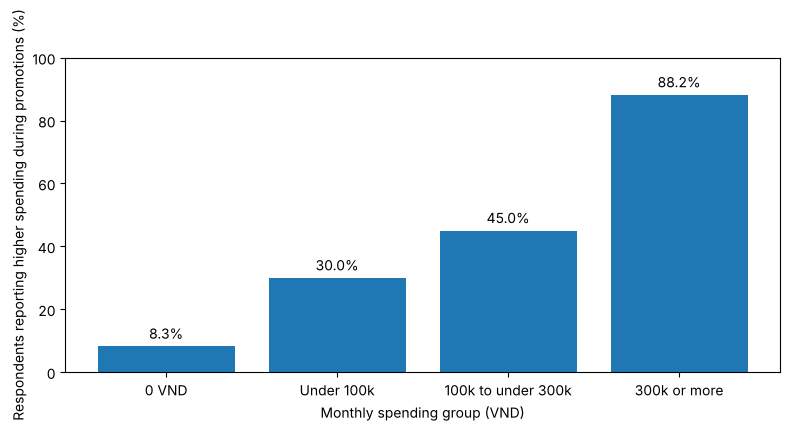

In [5]:
import matplotlib.pyplot as plt

# Tính tỷ lệ trả lời Yes trong từng nhóm chi tiêu tháng.
spending_groups = [0, 1, 2, 3]
yes_counts = observed.loc["Yes", spending_groups]
group_totals = observed[spending_groups].sum(axis=0)
yes_percent = 100 * yes_counts / group_totals

labels = ["0 VND", "Under 100k", "100k to under 300k", "300k or more"]

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(labels, yes_percent.to_numpy())

ax.bar_label(bars, labels=[f"{value:.1f}%" for value in yes_percent], padding=3)
ax.set_ylim(0, 100)
ax.set_xlabel("Monthly spending group (VND)")
ax.set_ylabel("Respondents reporting higher spending during promotions (%)")
fig.tight_layout()

# Lưu hình vào thư mục outputs (output_dir được tạo ở mục 4).
fig.savefig(output_dir / "figures" / "promotion_by_spending_group.png", dpi=300)

plt.show()

## 6. Sensitivity check: respondents with positive monthly spending

Of the 218 respondents who reported zero monthly spending, 18 reported
spending more during promotions. To examine whether the association
persists when this group is excluded, we repeat the chi-square test
among the 292 respondents who reported positive monthly spending.

This sensitivity check is reported separately from the five tests
included in the Holm correction.

In [6]:
# Chỉ giữ người đang nạp tiền hàng tháng (nhóm 1, 2, 3).
payers = df[df["SPEND_MONTH4"] > 0]
observed_payers = pd.crosstab(payers["PROMO"], payers["SPEND_MONTH4"])
display(observed_payers)

chi2_p, p_payers, dof_p, expected_p = chi2_contingency(observed_payers)
n_p = observed_payers.to_numpy().sum()
v_p = np.sqrt(chi2_p / (n_p * min(observed_payers.shape[0] - 1, observed_payers.shape[1] - 1)))

print(f"Minimum expected count: {expected_p.min():.2f}")
print(f"Chi-square({dof_p}) = {chi2_p:.4f}, p = {p_payers:.3g}")
print(f"n = {n_p}, Cramér's V = {v_p:.4f}")

SPEND_MONTH4,1.0,2.0,3.0
PROMO,,,
No,77,72,6
Yes,33,59,45


Minimum expected count: 23.93
Chi-square(2) = 47.7856, p = 4.2e-11
n = 292, Cramér's V = 0.4045


## 7. Interpretation

Perceived luck, perceived fairness of the pity system, and perceived price
fairness were each positively associated with satisfaction in the survey
sample. The corresponding Spearman correlations were 0.308, 0.443, and
0.454. Satisfaction was also positively associated with the intention to
keep playing (rho = 0.504, 95% CI [0.434, 0.570]).

Reporting higher spending during promotions was associated with monthly
spending group (chi-square(3) = 144.44, Cramér's V = 0.532). The share
reporting higher spending during promotions ranged from 8.3% in the
zero-monthly-spending group to 88.2% in the group spending at least
300,000 VND per month.

All five tests remained statistically significant after Holm correction
(adjusted p < 0.001). These results describe associations in the survey
sample. The cross-sectional, non-random survey limits causal inference
and generalization.

The association with promotions does not depend only on the zero-spending group. Among the 292 respondents who spend each month, it remained (chi-square(2) = 47.79, p < 0.001, Cramér's V = 0.405). This check is outside the Holm correction.